installing libraries

In [ ]:
!pip install sktime -q


In [ ]:
from sktime.datasets import load_plaid
import pandas as pd
import numpy as np

# Load the dataset
X, y = load_plaid()

print("Shape of X:", X.shape if hasattr(X, 'shape') else type(X))
print("Number of samples:", len(y))
print("Classes:", np.unique(y))
print("\nClass distribution:")
print(pd.Series(y).value_counts())

Shape of X: (1074, 1)
Number of samples: 1074
Classes: ['0' '1' '10' '2' '3' '4' '5' '6' '7' '8' '9']

Class distribution:
1     175
7     172
4     156
8     139
2     115
6     114
0      66
9      38
3      38
5      35
10     26
Name: count, dtype: int64


Quick look at the data

In [ ]:
# Show the first few labels
print(y[:10])

# See what one sample looks like
print("\nFirst sample type:", type(X.iloc[0] if hasattr(X, 'iloc') else X[0]))

['0' '0' '0' '0' '0' '0' '0' '0' '0' '0']

First sample type: <class 'pandas.core.series.Series'>


In [ ]:
import pandas as pd
import numpy as np
from sktime.datasets import load_plaid

X, y = load_plaid()

print("Type of X:", type(X))
print("Type of y:", type(y))
print("Length of dataset:", len(y))
print("\nUnique labels:")
print(np.unique(y))
print("\nLabel counts:")
print(pd.Series(y).value_counts().sort_index())

Type of X: <class 'pandas.core.frame.DataFrame'>
Type of y: <class 'numpy.ndarray'>
Length of dataset: 1074

Unique labels:
['0' '1' '10' '2' '3' '4' '5' '6' '7' '8' '9']

Label counts:
0      66
1     175
10     26
2     115
3      38
4     156
5      35
6     114
7     172
8     139
9      38
Name: count, dtype: int64


In [ ]:
# Show the first time series
sample = X.iloc[0, 0]   # first instance, first (and only) dimension
print("Length of first sample:", len(sample))
print("\nFirst 10 values of the current waveform:")
print(sample.head(10))
print("\nBasic statistics of first sample:")
print(sample.describe())

Length of first sample: 500

First 10 values of the current waveform:
0    0.173390
1    0.130450
2    0.134990
3    0.080702
4    0.136730
5    0.118690
6    0.105450
7    0.119360
8    0.074401
9    0.114620
dtype: float64

Basic statistics of first sample:
count    500.000000
mean      13.328743
std        6.155765
min        0.069973
25%       12.463000
50%       15.006500
75%       16.680000
max       21.898000
dtype: float64


Cell 2 – Feature Extraction

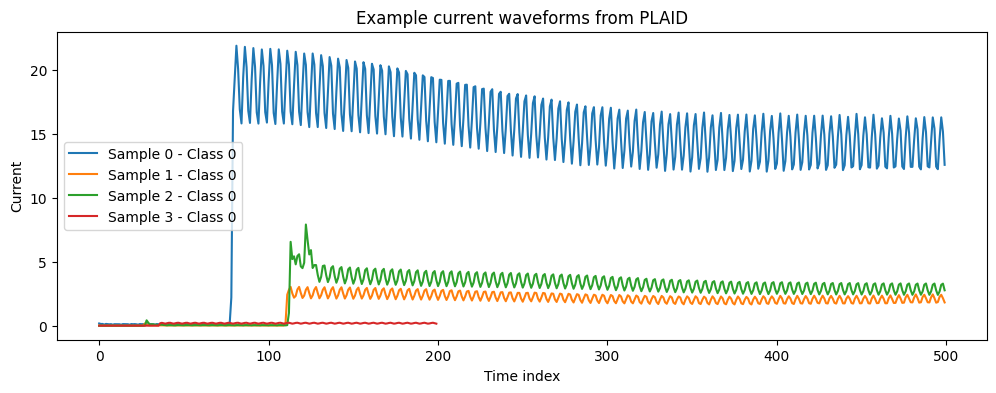

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
for i in range(4):
    plt.plot(X.iloc[i, 0].values, label=f"Sample {i} - Class {y[i]}")
plt.title("Example current waveforms from PLAID")
plt.xlabel("Time index")
plt.ylabel("Current")
plt.legend()
plt.show()

Cell 2 – Feature Extraction

In [ ]:
from tqdm.auto import tqdm

def extract_features(series):
    values = series.values.astype(float)
    return {
        'mean': np.mean(values),
        'std': np.std(values),
        'min': np.min(values),
        'max': np.max(values),
        'rms': np.sqrt(np.mean(values**2)),
        'peak_to_peak': np.ptp(values),
        'median': np.median(values),
        'q25': np.percentile(values, 25),
        'q75': np.percentile(values, 75),
    }

features_list = []
for i in tqdm(range(len(X)), desc="Extracting features"):
    series = X.iloc[i, 0]
    features_list.append(extract_features(series))

df_features = pd.DataFrame(features_list)
df_features['label'] = y

print("Feature matrix shape:", df_features.shape)
df_features.head()

Extracting features:   0%|          | 0/1074 [00:00<?, ?it/s]

Feature matrix shape: (1074, 10)


,mean,std,min,max,rms,peak_to_peak,median,q25,q75,label
0,13.328743,6.149606,0.069973,21.898000,14.679000,21.828027,15.006500,12.463000,16.680000,0
1,1.718599,0.956060,-0.003826,3.032800,1.966630,3.036626,2.085950,1.705600,2.336450,0
2,2.642613,1.535618,-0.004745,7.912200,3.056391,7.916945,3.103250,2.443675,3.544525,0
3,0.158513,0.077644,-0.000010,0.228400,0.176508,0.228410,0.184010,0.156740,0.214860,0
4,0.010254,0.005615,-0.000014,0.023028,0.011690,0.023042,0.009999,0.008501,0.011207,0


Cell 3 – Train / Test Split

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_encoded = le.fit_transform(df_features['label'])

X_feat = df_features.drop(columns=['label'])
y_feat = y_encoded

X_train, X_test, y_train, y_test = train_test_split(
    X_feat, y_feat,
    test_size=0.25,
    random_state=42,
    stratify=y_feat
)

print("Train size:", X_train.shape[0])
print("Test size :", X_test.shape[0])
print("Number of features:", X_train.shape[1])
print("\nClasses:", le.classes_)

Train size: 805
Test size : 269
Number of features: 9

Classes: ['0' '1' '10' '2' '3' '4' '5' '6' '7' '8' '9']


Cell 4 – Baseline + Proposed Models

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# ===== Baseline: Decision Tree =====
baseline = DecisionTreeClassifier(max_depth=8, random_state=42)
baseline.fit(X_train, y_train)
y_pred_base = baseline.predict(X_test)

print("="*55)
print("BASELINE – Decision Tree")
print("="*55)
print("Accuracy:", round(accuracy_score(y_test, y_pred_base), 4))
print(classification_report(y_test, y_pred_base, target_names=le.classes_))

# ===== Proposed: Random Forest =====
proposed = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)
proposed.fit(X_train, y_train)
y_pred_prop = proposed.predict(X_test)

print("\n" + "="*55)
print("PROPOSED MODEL – Random Forest")
print("="*55)
print("Accuracy:", round(accuracy_score(y_test, y_pred_prop), 4))
print(classification_report(y_test, y_pred_prop, target_names=le.classes_))

BASELINE – Decision Tree
Accuracy: 0.7695
              precision    recall  f1-score   support

           0       0.61      0.65      0.63        17
           1       0.87      0.75      0.80        44
          10       0.80      0.67      0.73         6
           2       0.57      0.69      0.62        29
           3       0.29      0.22      0.25         9
           4       0.87      0.85      0.86        39
           5       0.73      0.89      0.80         9
           6       0.70      0.79      0.74        29
           7       0.85      0.95      0.90        43
           8       0.93      0.80      0.86        35
           9       0.67      0.44      0.53         9

    accuracy                           0.77       269
   macro avg       0.72      0.70      0.70       269
weighted avg       0.78      0.77      0.77       269


PROPOSED MODEL – Random Forest
Accuracy: 0.8959
              precision    recall  f1-score   support

           0       1.00      0.76      0.

Next Cell – Confusion Matrix + Save Models

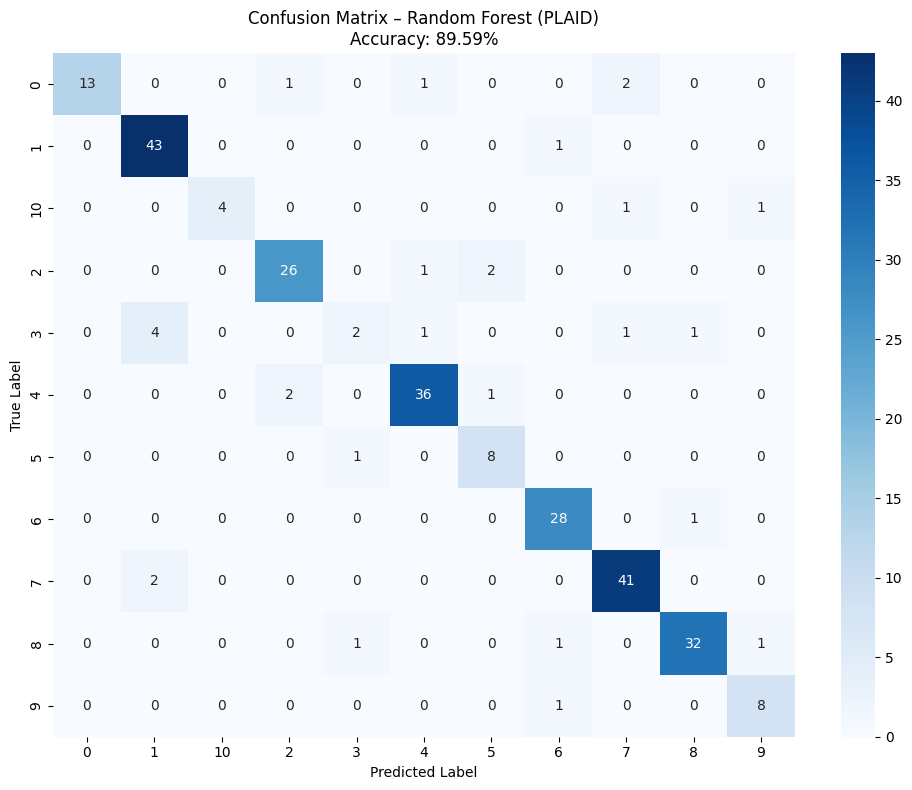

Models saved successfully:
- baseline_decision_tree.joblib
- proposed_random_forest.joblib
- label_encoder.joblib


In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_prop)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_,
            yticklabels=le.classes_)
plt.title("Confusion Matrix – Random Forest (PLAID)\nAccuracy: 89.59%")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# Save models
joblib.dump(baseline, "baseline_decision_tree.joblib")
joblib.dump(proposed, "proposed_random_forest.joblib")
joblib.dump(le, "label_encoder.joblib")

print("Models saved successfully:")
print("- baseline_decision_tree.joblib")
print("- proposed_random_forest.joblib")
print("- label_encoder.joblib")

Cell – Admission Logic

In [ ]:
import random

# Approximate power for each appliance class (Watts)
power_estimates = {
    '0': 1200,   # Air Conditioner
    '1': 15,     # CFL
    '2': 50,     # Fan
    '3': 150,    # Fridge
    '4': 1500,   # Hairdryer
    '5': 1500,   # Heater
    '6': 60,     # Incandescent bulb
    '7': 60,     # Laptop
    '8': 1200,   # Microwave
    '9': 1000,   # Vacuum
    '10': 500,   # Washing Machine
}

def improved_admission(predicted_label, current_soc=55, available_pv=300,
                       battery_capacity_wh=600, essential_reserve_w=200):
    """
    Improved admission decision with ALLOW / DELAY / REJECT
    """
    pred_label = str(predicted_label)
    predicted_power = power_estimates.get(pred_label, 400)

    # Available power from battery at current SOC (simplified)
    usable_battery_power = (current_soc / 100) * 800   # rough max discharge power

    total_available = available_pv + usable_battery_power
    net_available = total_available - essential_reserve_w

    # Decision rules
    if predicted_power <= net_available and current_soc > 40:
        decision = "ALLOW"
    elif predicted_power <= net_available + 400 and current_soc > 30:
        decision = "DELAY"          # Can wait for better PV / higher SOC
    else:
        decision = "REJECT"

    return {
        "decision": decision,
        "predicted_power": predicted_power,
        "current_soc": current_soc,
        "net_available": round(net_available, 1)
    }


# ===== Test the improved logic =====
print(f"{'True':<6} {'Pred':<6} {'Power':<8} {'SOC':<6} {'Available':<10} {'Decision'}")
print("-" * 55)

for i in range(20):
    true_label = le.inverse_transform([y_test[i]])[0]
    pred_label = le.inverse_transform([y_pred_prop[i]])[0]

    # Simulate different SOC values
    soc = random.choice([35, 45, 55, 65, 75])

    result = improved_admission(pred_label, current_soc=soc, available_pv=250)

    print(f"{true_label:<6} {pred_label:<6} {result['predicted_power']:<8} "
          f"{result['current_soc']:<6} {result['net_available']:<10} {result['decision']}")

True   Pred   Power    SOC    Available  Decision
-------------------------------------------------------
1      1      15       65     570.0      ALLOW
1      1      15       65     570.0      ALLOW
7      7      60       55     490.0      ALLOW
4      4      1500     75     650.0      REJECT
0      0      1200     55     490.0      REJECT
6      6      60       75     650.0      ALLOW
7      7      60       75     650.0      ALLOW
6      6      60       35     330.0      DELAY
8      8      1200     35     330.0      REJECT
0      0      1200     35     330.0      REJECT
1      1      15       35     330.0      DELAY
2      2      50       65     570.0      ALLOW
3      3      150      35     330.0      DELAY
8      8      1200     75     650.0      REJECT
8      8      1200     45     410.0      REJECT
4      4      1500     55     490.0      REJECT
1      1      15       45     410.0      ALLOW
6      6      60       55     490.0      ALLOW
7      7      60       65     570.0      